# DATA3320 Lecture 11 Class Demo: Descriptive Statistics

**Business context:** A healthcare network wants to understand patient wait times before making staffing and service-design decisions.

> Run the notebook from top to bottom. Activities are designed for individual work followed by brief whole-class discussion.


## Course-material references
This class demo expands and applies the following Week 7 materials:

- **Lecture 11 presentation:** `Lecture11_descriptive_stat.pptx`
  - statistics and descriptive versus inferential statistics
  - frequency distributions
  - measures of central tendency
  - measures of dispersion
  - normal distributions and skewness


### Online course links 
- [Lecture 11 recording](https://nait.video.yuja.com/V/Video?v=1349732&node=7568833&a=1129242952)
- [Original Lecture 11 notebook](https://nbviewer.org/github/Dong2Yo/PredcitiveAnalysis_BusinessProfessional/blob/main/lectures/Lecture11_descriptive_statistics.ipynb)
- [Lecture 11–12 workbook](https://github.com/Dong2Yo/PredcitiveAnalysis_BusinessProfessional/blob/main/workbooks/Lecture11_12_Workbook.ipynb)
- [Workbook solution](https://colab.research.google.com/drive/1RvKxMns7J_ppjzlXISrwtBAxCAzTalBe?usp=sharing)
- [Introduction to Descriptive Statistics reading](https://www.sydney.edu.au/content/dam/students/documents/mathematics-learning-centre/introduction-to-descriptive-statistics.pdf)


## Google Colab instructions
1. Download this `.ipynb` file.
2. Open [Google Colab](https://colab.research.google.com/).
3. Select **File → Upload notebook** and choose the downloaded file.
4. Run cells from top to bottom.
5. Complete each exercise before opening its hint or solution.
6. Save a copy to Google Drive if you want to retain your work.

The notebook creates its dataset internally and requires no separate CSV.


## Learning outcomes
By the end of class, students should be able to:
1. Distinguish categorical and numerical variables.
2. Build and interpret frequency tables.
3. Calculate mean, median, and mode.
4. Calculate range, IQR, variance, and standard deviation.
5. Interpret histograms, boxplots, distribution shape, and outliers.
6. Select statistics that support a defensible business conclusion.


## Theory: What does descriptive statistics do
Descriptive statistics organize, summarize, and display observed data. They help answer three connected questions:

1. **Centre:** What value is typical?
2. **Spread:** How much do observations vary?
3. **Shape:** Is the distribution symmetric, skewed, clustered, or affected by unusual values?

Descriptive statistics describe the available observations. They do not, by themselves, prove cause and effect or establish that a sample represents a broader population.


> **Presentation connection:** Review the Lecture 11 presentation sections on *Statistics*, *Types of Statistics*, and *Reasons for Using Statistics*. The notebook applies those ideas to a synthetic healthcare operations case.


### Theory reference: choosing a summary
- Use **counts and proportions** for categorical variables.
- Use **mean and standard deviation** when numerical data are reasonably symmetric and extreme values are not dominating.
- Use **median and IQR** when numerical data are skewed or contain influential extreme observations.
- Use a **histogram** to examine numerical distribution shape.
- Use a **boxplot** to compare centre, spread, and potential outliers.

A responsible analysis combines numerical summaries, visual evidence, and business context.


## Today's learning path

1. **Business challenge and prediction** (0–10 min)
2. **Understand the dataset and frequency summaries** (10–25 min)
3. **Measures of centre** (25–42 min)
4. **Visualize centre, shape, and unusual values** (42–57 min)
5. **Measures of spread and clinic comparison** (57–72 min)
6. **Pause and reset** (72–77 min)
7. **Outliers, skewness, and responsible interpretation** (77–92 min)
8. **Executive decision challenge** (92–105 min)
9. **Exit check** (105–110 min)


## How to use this notebook
- Run cells in order.
- For every **Stop and Predict**, write an answer before running the next cell.
- Complete each **Try It** independently first.
- Interpret outputs in words. Code output is not a business conclusion by itself.
- Use careful language: describe what the data show without inventing causes.


In [7]:
# Environment and dependency check
# Required third-party packages: pandas, numpy, matplotlib
import sys
from importlib.util import find_spec

required_packages = ["pandas", "numpy", "matplotlib"]
missing_packages = [pkg for pkg in required_packages if find_spec(pkg) is None]

print("Python version:", sys.version.split()[0])
if missing_packages:
    raise ModuleNotFoundError(
        "Missing package(s): " + ", ".join(missing_packages) +
        ". Install them before running this notebook, for example: " +
        "pip install pandas numpy matplotlib"
    )
print("Dependency check passed:", ", ".join(required_packages))


Python version: 3.12.8
Dependency check passed: pandas, numpy, matplotlib


## 1. Healthcare analytics challenge (0–10 min)

A healthcare network asks:

> **Should another nurse be scheduled because the patient wait time is too long?**

Before computing anything, list the evidence needed to answer responsibly. Consider centre, variability, clinic differences, unusual waits, sample size, and operational context.

### Stop and Predict
For `8, 9, 10, 11, 12, 13, 95`:
1. Which value appears unusual?
2. Will the mean be above or below the median?
3. Which value might better represent a typical wait? Why?

In [9]:
wait_warmup = [8, 9, 10, 11, 12, 13, 95]
import statistics as stats
print("Mean:", round(stats.mean(wait_warmup), 2))
print("Median:", stats.median(wait_warmup))


Mean: 22.57
Median: 11


### Checkpoint
The mean uses every value, so an extreme value can pull it upward. The median depends on position and is usually more resistant to an extreme observation.

**Business caution:** Do not choose a statistic only because it looks favourable. Choose it because it represents the distribution appropriately.


## 2. Setup: a small healthcare dataset (8–20 min)
The dataset is created inside the notebook, so no external file is required.


In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Synthetic classroom dataset: 36 patient visits across three clinics.
# The values are designed for learning and are not real patient records.
patients = pd.DataFrame({
    "patient_id": range(1001, 1037),
    "clinic": (["North"] * 12) + (["Central"] * 12) + (["South"] * 12),
    "visit_type": ["Booked","Booked","Walk-in","Booked","Walk-in","Booked","Booked","Walk-in","Booked","Walk-in","Booked","Walk-in"] * 3,
    "age": [24,38,61,45,29,53,67,34,48,72,41,56,
            22,35,58,43,31,65,51,39,47,70,44,60,
            25,37,59,46,30,64,52,40,49,73,42,57],
    "wait_minutes": [14,18,20,22,25,17,19,24,21,23,16,20,
                     28,32,35,38,42,31,36,45,34,40,33,37,
                     24,27,30,33,36,29,34,41,31,38,95,110],
    "satisfaction": [5,5,4,4,4,5,5,4,4,4,5,4,
                     4,4,4,3,3,4,3,3,4,3,4,3,
                     4,4,4,3,3,4,3,3,4,3,1,1]
})
patients.head()

,patient_id,clinic,visit_type,age,wait_minutes,satisfaction
0,1001,North,Booked,24,14,5
1,1002,North,Booked,38,18,5
2,1003,North,Walk-in,61,20,4
3,1004,North,Booked,45,22,4
4,1005,North,Walk-in,29,25,4


### Variable types
- **Categorical:** labels or groups, such as clinic and visit type.
- **Numerical:** measured or counted values, such as age and wait time.
- **Discrete:** countable values, often whole numbers.
- **Continuous:** measurements that can conceptually take values within a range.

### Try It 1 (4 min)
Classify `clinic`, `visit_type`, `age`, `wait_minutes`, and `satisfaction`. Be prepared to explain one ambiguous choice.


<details><summary><strong>Click to show hint: Variable types</strong></summary>

Review the relevant theory and identify the required inputs, operation, and interpretation before opening the solution.

</details>


<details>
<summary><strong>Click to show solution: Variable types</strong></summary>

- `clinic`: categorical, nominal
- `visit_type`: categorical, nominal
- `age`: numerical; usually treated as continuous in analysis, although recorded here in whole years
- `wait_minutes`: numerical and conceptually continuous, although rounded here
- `satisfaction`: ordinal; the order is meaningful, but equal spacing between ratings should not be assumed automatically

</details>


<details><summary><strong>Click to show explanation: Variable types</strong></summary>

Variable type determines which summaries and charts are defensible. Satisfaction is ordinal: values have an order, but an equal numerical gap between adjacent ratings should not be assumed automatically.

</details>


In [13]:
patients.dtypes


patient_id       int64
clinic          object
visit_type      object
age              int64
wait_minutes     int64
satisfaction     int64
dtype: object

## 3. Frequency distributions (20–35 min)
A frequency table shows how often each category or value occurs. Relative frequency expresses the count as a proportion or percentage.


> **Presentation connection:** This section applies the presentation’s frequency-distribution concepts by calculating both counts and percentages for healthcare categories.


In [15]:
clinic_frequency = patients["clinic"].value_counts()
clinic_percent = patients["clinic"].value_counts(normalize=True).mul(100).round(1)
pd.DataFrame({"Frequency": clinic_frequency, "Percent": clinic_percent})


,Frequency,Percent
clinic,,
North,12,33.3
Central,12,33.3
South,12,33.3


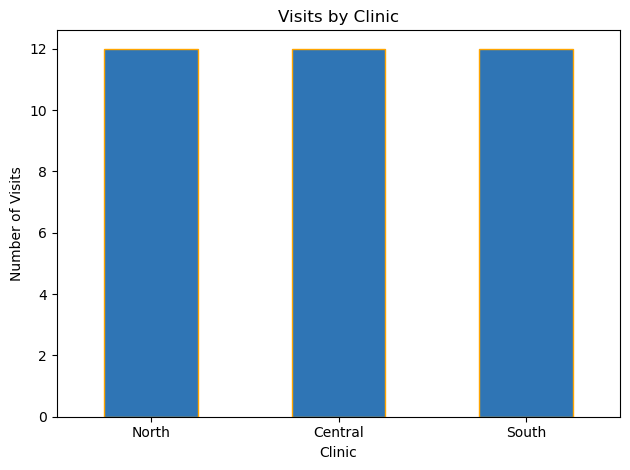

In [17]:
clinic_frequency.plot(kind="bar", color="#2F75B5", edgecolor="orange")
plt.title("Visits by Clinic")
plt.xlabel("Clinic")
plt.ylabel("Number of Visits")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### Try It 2 (6 min)
1. Create a frequency and percentage table for `visit_type`.
2. Make an appropriate chart.
3. Write one accurate observation without claiming cause and effect.


<details><summary><strong>Click to show hint: Frequency-table interpretation</strong></summary>

Review the relevant theory and identify the required inputs, operation, and interpretation before opening the solution.

</details>


<details>
<summary><strong>Click to show solution: Frequency-table interpretation</strong></summary>

A correct response should report both count and percentage. An appropriate observation is: “The sample contains both booked and walk-in visits.” Avoid claiming that one visit type causes longer waits unless wait time is analyzed by visit type.

</details>


<details><summary><strong>Click to show explanation: Frequency-table interpretation</strong></summary>

Counts describe how many observations fall in each category; percentages make categories easier to compare. Neither summary establishes that visit type causes any difference in wait time.

</details>


In [19]:
# YOUR TURN: complete the code
visit_counts = patients["visit_type"].value_counts()
visit_percent = patients["visit_type"].value_counts(normalize=True).mul(100).round(1)
pd.DataFrame({"Frequency": visit_counts, "Percent": visit_percent})


,Frequency,Percent
visit_type,,
Booked,21,58.3
Walk-in,15,41.7


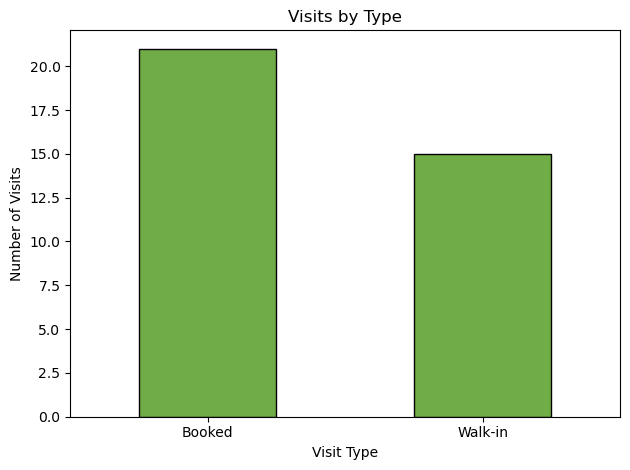

In [21]:
visit_counts.plot(kind="bar", color="#70AD47", edgecolor="black")
plt.title("Visits by Type")
plt.xlabel("Visit Type")
plt.ylabel("Number of Visits")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 4. Measures of centre (35–52 min)
- **Mean:** arithmetic average; uses every value.
- **Median:** middle ordered value; resistant to extreme observations.
- **Mode:** most frequently occurring value; applicable to categorical and numerical data.


> **Presentation connection:** This section corresponds to the presentation’s measures of central tendency: mode, median, and mean, including the mean’s sensitivity to extreme values.


### Theory: centre

For observations $x_1, x_2, \ldots, x_n$:

$$
\bar{x} = \frac{\sum_{i=1}^{n} x_i}{n}
$$
- The **mean** balances all observations and is sensitive to extreme values.
- The **median** is the middle ordered value and is resistant to extreme values.
- The **mode** is the most frequent value. A dataset can have one mode, several modes, or no uniquely useful mode.


In [25]:
wait_mean = patients["wait_minutes"].mean()
wait_median = patients["wait_minutes"].median()
wait_modes = patients["wait_minutes"].mode().tolist()
print(f"Mean wait: {wait_mean:.2f} minutes")
print(f"Median wait: {wait_median:.2f} minutes")
print("Mode(s):", wait_modes)


Mean wait: 33.28 minutes
Median wait: 31.00 minutes
Mode(s): [20, 24, 31, 33, 34, 36, 38]


### Interpretation checkpoint
If the mean and median differ noticeably, inspect the distribution. The difference may reflect skewness or an influential extreme value. A difference alone is not proof of data error.


In [24]:
patients.groupby("clinic")["wait_minutes"].agg(["count", "mean", "median"]).round(2)


,count,mean,median
clinic,,,
Central,12,35.92,35.5
North,12,19.92,20.0
South,12,44.00,33.5


### Data Detective Challenge
Two clinics both report an average wait of 20 minutes. Is that enough to say their performance is similar?

**Stop and Predict:** Which additional statistics or visualizations would you request?


In [26]:
detective = pd.DataFrame({
    "Clinic A": [18, 19, 20, 20, 21, 22],
    "Clinic B": [5, 10, 15, 25, 30, 35]
})
detective.agg(["mean", "median", "std", "min", "max"]).round(2)


,Clinic A,Clinic B
mean,20.00,20.00
median,20.00,20.00
std,1.41,11.83
min,18.00,5.00
max,22.00,35.00


### Discuss
- The means are equal. What is different?
- Which clinic is more predictable?
- Why can an average alone create an incomplete story?


### Try It 3 (5 min)
Compare the clinics using both mean and median.
- Does the same clinic look best under both measures?
- What additional information would you want before recommending staffing changes?


<details><summary><strong>Click to show hint: Comparing clinics with centre</strong></summary>

Review the relevant theory and identify the required inputs, operation, and interpretation before opening the solution.

</details>


<details>
<summary><strong>Click to show solution: Comparing clinics with centre</strong></summary>

Compare both mean and median. If they tell different stories, inspect the distribution and potential outliers. A staffing recommendation would also need visit volume, patient acuity, time of day, staffing levels, and whether the sample reflects normal operations.

</details>


<details><summary><strong>Click to show explanation: Comparing clinics with centre</strong></summary>

Mean and median answer related but different questions. A large difference between them should lead you to inspect skewness, outliers, and the underlying operational context before recommending action.

</details>


## 5. Measures of spread (52–70 min)
Centre does not tell us whether observations are tightly clustered or widely dispersed.

- **Range:** maximum minus minimum.
- **IQR:** Q3 minus Q1; spread of the middle 50%.
- **Variance:** average squared distance from the mean, using a sample or population formula.
- **Standard deviation:** square root of variance, expressed in the original unit.


> **Presentation connection:** This section applies the presentation’s range, variance, and standard-deviation concepts and adds IQR for resistant spread measurement.


### Theory: spread
- **Range:** $\max(x)-\min(x)$
- **IQR:** $Q_3-Q_1$, covering the middle 50% of observations
- **Sample variance:** $s^2 = \frac{\sum_{i=1}^{n}(x_i-\bar{x})^2}{n-1}$
- **Sample standard deviation:** $s=\sqrt{s^2}$

Standard deviation is expressed in the original measurement unit. IQR is resistant to extreme values and works well with the median.


In [37]:
wait = patients["wait_minutes"]
q1 = wait.quantile(0.25)
q3 = wait.quantile(0.75)
summary = {
    "Minimum": wait.min(),
    "Maximum": wait.max(),
    "Range": wait.max() - wait.min(),
    "Q1": q1,
    "Median": wait.median(),
    "Q3": q3,
    "IQR": q3 - q1,
    "Sample variance": wait.var(ddof=1),
    "Sample standard deviation": wait.std(ddof=1)
}
pd.Series(summary).round(2)


Minimum                       14.00
Maximum                      110.00
Range                         96.00
Q1                            22.75
Median                        31.00
Q3                            36.25
IQR                           13.50
Sample variance              358.55
Sample standard deviation     18.94
dtype: float64

### Sample versus population
Pandas uses the **sample** formula by default for `.var()` and `.std()` (`ddof=1`). Use `ddof=0` when the data represent the complete population of interest.


In [31]:
print("Sample SD:", round(wait.std(ddof=1), 2))
print("Population SD:", round(wait.std(ddof=0), 2))


Sample SD: 18.94
Population SD: 18.67


### Try It 4 (5 min)
Two clinics can have the same mean but different consistency. Run the next cell and decide which clinic offers the more predictable wait.


<details><summary><strong>Click to show hint: Which clinic is more predictable?</strong></summary>

Review the relevant theory and identify the required inputs, operation, and interpretation before opening the solution.

</details>


<details>
<summary><strong>Click to show solution: Which clinic is more predictable?</strong></summary>

Clinic A is more predictable because its observations are tightly clustered and its standard deviation and range are smaller. The two clinics have similar centres, but very different variability.

</details>


<details><summary><strong>Click to show explanation: Which clinic is more predictable?</strong></summary>

Clinic A is more predictable because its observations are more tightly clustered. Similar means can hide major differences in variability, so centre and spread should be reported together.

</details>


In [33]:
clinic_a = pd.Series([18, 19, 20, 20, 21, 22])
clinic_b = pd.Series([5, 10, 15, 25, 30, 35])
comparison = pd.DataFrame({
    "Mean": [clinic_a.mean(), clinic_b.mean()],
    "Median": [clinic_a.median(), clinic_b.median()],
    "SD": [clinic_a.std(), clinic_b.std()],
    "Range": [clinic_a.max()-clinic_a.min(), clinic_b.max()-clinic_b.min()]
}, index=["Clinic A", "Clinic B"])
comparison.round(2)


,Mean,Median,SD,Range
Clinic A,20.0,20.0,1.41,4
Clinic B,20.0,20.0,11.83,30


## Pause and Reset (70–75 min)
Save the notebook and return ready to interpret distribution shape.


## 6. Histograms, boxplots, and skewness (75–92 min)
A histogram emphasizes distribution shape. A boxplot emphasizes median, quartiles, spread, and potential outliers.


> **Presentation connection:** This section connects to the presentation’s normal-distribution and skewness discussion and uses Python charts to inspect distribution shape.


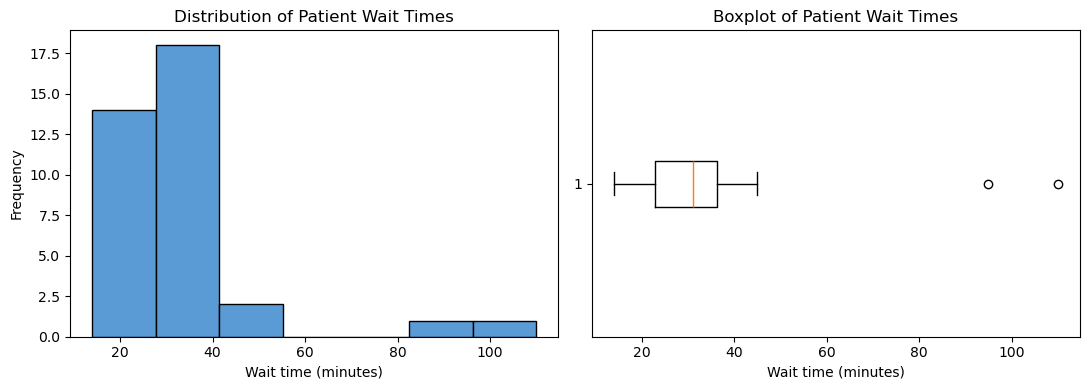

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(wait, bins=7, color="#5B9BD5", edgecolor="black")
axes[0].set_title("Distribution of Patient Wait Times")
axes[0].set_xlabel("Wait time (minutes)")
axes[0].set_ylabel("Frequency")
axes[1].boxplot(wait, vert=False)
axes[1].set_title("Boxplot of Patient Wait Times")
axes[1].set_xlabel("Wait time (minutes)")
plt.tight_layout()
plt.show()


In [37]:
print("Skewness:", round(wait.skew(), 3))
print("Mean:", round(wait.mean(), 2), "Median:", wait.median())


Skewness: 2.92
Mean: 33.28 Median: 31.0


### Reading skewness
- Positive skew: longer right tail.
- Negative skew: longer left tail.
- Near zero: more symmetric, though symmetry should also be checked visually.

Skewness is descriptive, not a diagnosis of why the pattern occurred.


In [39]:
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
potential_outliers = patients[(patients["wait_minutes"] < lower_fence) | (patients["wait_minutes"] > upper_fence)]
print("Lower fence:", lower_fence)
print("Upper fence:", upper_fence)
potential_outliers[["patient_id", "clinic", "wait_minutes"]]


Lower fence: 2.5
Upper fence: 56.5


,patient_id,clinic,wait_minutes
34,1035,South,95
35,1036,South,110


### Try It 5 (6 min)
1. Identify potential outliers using the IQR rule.
2. Recalculate the mean after excluding those observations for comparison.
3. Do **not** automatically delete them. List two questions that should be investigated first.


<details><summary><strong>Click to show hint: Outlier investigation</strong></summary>

Review the relevant theory and identify the required inputs, operation, and interpretation before opening the solution.

</details>


<details>
<summary><strong>Click to show solution: Outlier investigation</strong></summary>

Before removal, ask: Was the value entered correctly? Did an unusual operational event occur? Was patient acuity different? Is the long wait a valid and important service failure? Compare results with and without flagged values, but do not delete valid observations merely because they are inconvenient.

</details>


<details><summary><strong>Click to show explanation: Outlier investigation</strong></summary>

The IQR rule flags observations for review; it does not prove data error. Valid extreme waits may be the most operationally important cases and should not be removed merely to improve a summary.

</details>


In [41]:
filtered_wait = wait[(wait >= lower_fence) & (wait <= upper_fence)]
print("Original mean:", round(wait.mean(), 2))
print("Comparison mean without IQR-flagged values:", round(filtered_wait.mean(), 2))
print("Original median:", wait.median())
print("Comparison median:", filtered_wait.median())


Original mean: 33.28
Comparison mean without IQR-flagged values: 29.21
Original median: 31.0
Comparison median: 30.5


## Healthcare Finding Lab
This synthetic case contains clear operational patterns. Your task is to discover them rather than being told where they are.

### Student Work
1. Compare wait time by clinic.
2. Compare satisfaction by clinic.
3. Calculate the correlation between wait time and satisfaction.
4. Identify potential outliers.
5. State the two most decision-relevant findings.

Use “associated with” rather than causal language.


### Colab Exercise
Run the provided analysis, then create one additional visualization that supports a clinic comparison. Add a new code cell below and write a two-sentence interpretation.


<details><summary><strong>Click to show hint: Healthcare visualization</strong></summary>

Try a clinic-level boxplot or a bar chart of median wait time. Include a title and labelled axes.

</details>


<details><summary><strong>Click to show solution: Healthcare visualization</strong></summary>

One valid option is:

```python
patients.boxplot(column="wait_minutes", by="clinic", grid=False)
plt.suptitle("")
plt.title("Patient Wait Time by Clinic")
plt.xlabel("Clinic")
plt.ylabel("Wait time in minutes")
plt.show()
```

A strong interpretation identifies shorter, more consistent North waits and larger South variability, while avoiding unsupported causal explanations.

</details>


<details><summary><strong>Click to show explanation: Healthcare visualization</strong></summary>

A visualization should support the same conclusion as the numerical summary. The boxplot makes clinic differences in centre, spread, and extreme values visible, but it does not explain their causes.

</details>


In [43]:
# STUDENT WORK: complete or adapt these lines
clinic_findings = patients.groupby("clinic").agg(
    visits=("patient_id", "count"),
    mean_wait=("wait_minutes", "mean"),
    median_wait=("wait_minutes", "median"),
    wait_sd=("wait_minutes", "std"),
    mean_satisfaction=("satisfaction", "mean")
).round(2)

wait_satisfaction_correlation = patients["wait_minutes"].corr(patients["satisfaction"])

clinic_findings, round(wait_satisfaction_correlation, 3)


(         visits  mean_wait  median_wait  wait_sd  mean_satisfaction
 clinic                                                             
 Central      12      35.92         35.5     4.83               3.50
 North        12      19.92         20.0     3.32               4.42
 South        12      44.00         33.5    27.91               3.08,
 -0.899)

<details><summary><strong>Click to show hint: Healthcare Finding Lab</strong></summary>

Review the relevant theory and identify the required inputs, operation, and interpretation before opening the solution.

</details>


<details>
<summary><strong>Click to show solution: Healthcare Finding Lab</strong></summary>

With this synthetic classroom dataset:

- North has the shortest and most consistent waits.
- South shows the greatest variability and contains the longest waits.
- In this synthetic dataset, longer waits are associated with lower satisfaction ratings.
- The correlation between wait time and satisfaction is negative, indicating association in this dataset, not proof that wait time alone causes satisfaction ratings.

A strong recommendation is to investigate the South clinic’s long-wait cases and operational conditions before making staffing changes.

</details>


<details><summary><strong>Click to show explanation: Healthcare Finding Lab</strong></summary>

The correct language is association, not causation. In this synthetic dataset, longer waits are associated with lower satisfaction ratings, while South has the greatest variability and longest waits. Additional operational evidence is needed before explaining why.

</details>


## 7. Integrated mini-case (92–105 min)
Management asks: **Which clinic should be investigated first for wait-time improvement?**

Work independently first, then compare your reasoning with the class:
1. Calculate count, mean, median, standard deviation, minimum, and maximum by clinic.
2. Create one chart.
3. Write a three-sentence recommendation:
   - finding,
   - evidence,
   - limitation or next step.


In [45]:
clinic_summary = patients.groupby("clinic")["wait_minutes"].agg(
    count="count", mean="mean", median="median", sd="std", minimum="min", maximum="max"
).round(2)
clinic_summary


,count,mean,median,sd,minimum,maximum
clinic,,,,,,
Central,12,35.92,35.5,4.83,28,45
North,12,19.92,20.0,3.32,14,25
South,12,44.00,33.5,27.91,24,110


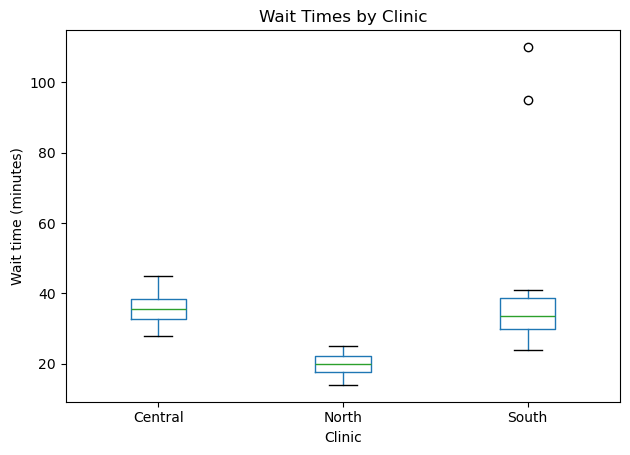

In [47]:
patients.boxplot(column="wait_minutes", by="clinic", grid=False)
plt.suptitle("")
plt.title("Wait Times by Clinic")
plt.xlabel("Clinic")
plt.ylabel("Wait time (minutes)")
plt.tight_layout()
plt.show()


### Executive Brief: maximum 50 words
Write exactly three parts:
1. **Finding:** the most decision-relevant pattern.
2. **Evidence:** statistics and/or visualization supporting the finding.
3. **Action and limitation:** a reasonable next step plus one caution.

Do not claim that the descriptive data prove why the pattern occurred.

## 8. Exit ticket (105–110 min)
Answer without running code first:
1. When is the median preferable to the mean?
2. What does standard deviation add beyond the mean?
3. Why should a potential outlier be investigated before removal?
4. Which combination is stronger: one statistic alone, or statistics plus visualization? Why?


## Key takeaways
- Describe centre, spread, and shape together.
- Match statistics to variable type and distribution.
- Use visualizations to reveal what a single number can hide.
- Separate observation from causal explanation.
- Translate statistical output into a careful business recommendation.


### Important language note
In this lesson, “significant finding” means **important for a business decision**. It does not mean “statistically significant.” Statistical significance requires an inferential method, a defined hypothesis, and appropriate assumptions beyond this descriptive lesson.
